# Challenge 4: Quantum Correlation Switch

## Prediction Before Execution

### Predictions:
1. **Part A (Correlated Outcomes):**
   - **Circuit State:** Creates the Bell state $\vert{}\Phi^+\rangle = \frac{\vert{}00\rangle + \vert{}11\rangle}{\sqrt{2}}$ using a Hadamard ($H$) on qubit 0 and a CNOT ($CX$) with control qubit 0 and target qubit 1.
   - **Dominant Outcomes:** `00` and `11` should dominate (roughly 50% each).
   - **Expected Behavior:** Outcomes `01` and `10` should ideally be 0, though a very small number of counts may appear due to hardware/readout noise on the real QPU.

2. **Part B (Opposite / Anti-correlated Outcomes):**
   - **Circuit State:** Switches correlation by inserting an $X$ gate on qubit 1 after the CNOT, generating $\vert{}\Psi^+\rangle = \frac{\vert{}01\rangle + \vert{}10\rangle}{\sqrt{2}}$.
   - **Dominant Outcomes:** `01` and `10` will dominate (roughly 50% each).
   - **Expected Behavior:** `00` and `11` will drop to near zero.

3. **Why are some outcomes much more frequent than others?**
   - In quantum superposition and entanglement, the quantum amplitudes determine outcome probabilities ($P = \vert{}\alpha\vert{}^2$). In Part A, amplitudes for $\vert{}01\rangle$ and $\vert{}10\rangle$ are theoretically 0, while $\vert{}00\rangle$ and $\vert{}11\rangle$ each have probability $1/2$. Part B shifts the amplitude to $\vert{}01\rangle$ and $\vert{}10\rangle$ through a bit-flip on one qubit.

In [1]:
# Cell 2: Connect to IBM Quantum Service and Hardware Backend
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Load saved IBM Quantum Platform credentials
service = QiskitRuntimeService()

# Select the least busy operational real quantum computer
backend = service.least_busy(operational=True, simulator=False)
print(f"Connected to backend: {backend.name}")

Connected to backend: ibm_fez


## Part A: Correlated Outcomes Circuit (00 and 11)
Design a two-qubit circuit producing predominantly `00` and `11` using $\le 4$ quantum gates.

Circuit Part A (Correlated Outcomes):


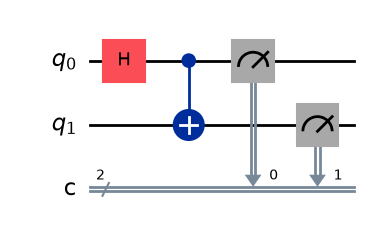

In [3]:
# Cell 4: Circuit for Part A
qc_part_a = QuantumCircuit(2, 2)
qc_part_a.h(0)           # Superposition on qubit 0
qc_part_a.cx(0, 1)       # Entangle qubit 0 and qubit 1
qc_part_a.measure([0, 1], [0, 1])

print("Circuit Part A (Correlated Outcomes):")
display(qc_part_a.draw('mpl'))

## Part B: Opposite Outcomes Circuit (01 and 10)
Modify the circuit using a correlation switch (adding an $X$ gate on qubit 1) to produce predominantly `01` and `10`. Total gates before measurement: 3 (within the 4-gate constraint).

Circuit Part B (Opposite Outcomes):


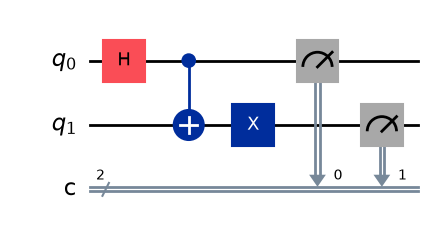

In [4]:
# Cell 6: Circuit for Part B
qc_part_b = QuantumCircuit(2, 2)
qc_part_b.h(0)
qc_part_b.cx(0, 1)
qc_part_b.x(1)           # Switch correlation from same to opposite
qc_part_b.measure([0, 1], [0, 1])

print("Circuit Part B (Opposite Outcomes):")
display(qc_part_b.draw('mpl'))

## Execution on IBM Quantum Hardware (100 Shots per Experiment)
Transpiling both circuits to target backend ISA and running for 100 shots each.

In [6]:
# Cell 8: Transpile and run on real IBM QPU
pm = generate_preset_pass_manager(target=backend.target, optimization_level=3)
qc_a_isa = pm.run(qc_part_a)
qc_b_isa = pm.run(qc_part_b)

sampler = Sampler(mode=backend)
shots = 100

print(f"Submitting Part A and Part B to {backend.name} for {shots} shots each...")
job = sampler.run([qc_a_isa, qc_b_isa], shots=shots)
print(f"Job ID: {job.job_id()}")
print("Waiting for job execution to complete...")

result = job.result()


C:\Users\surya\AppData\Local\Temp\ipykernel_15572\3706584047.py:6: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Submitting Part A and Part B to ibm_fez for 100 shots each...
Job ID: db5p4hklf4us73c4c530
Waiting for job execution to complete...


In [7]:
# Extract measurement counts from the classical register ('c')
counts_a = result[0].data.c.get_counts()
counts_b = result[1].data.c.get_counts()

print("\n--- Measurement Results (100 Shots) ---")
print(f"Part A Counts: {counts_a}")
print(f"Part B Counts: {counts_b}")


--- Measurement Results (100 Shots) ---
Part A Counts: {'11': 48, '00': 48, '10': 3, '01': 1}
Part B Counts: {'10': 50, '01': 48, '00': 1, '11': 1}


## Part C: Comparison & Histograms
Visualizing the results side-by-side to compare the distribution of measurement outcomes.


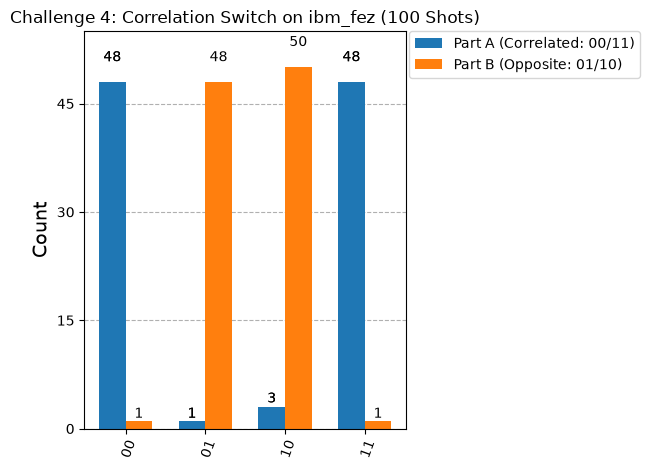

In [8]:
# Cell 10: Histogram Comparison
plot_histogram(
    [counts_a, counts_b],
    legend=['Part A (Correlated: 00/11)', 'Part B (Opposite: 01/10)'],
    title=f"Challenge 4: Correlation Switch on {backend.name} (100 Shots)"
)

## Explanation & Analysis

### 1. Which outcomes are dominant in Part A?
- **Outcomes `00` and `11`** dominate Part A[cite: 3]. The qubits are entangled in identical states, so whenever qubit 0 is measured as 0, qubit 1 is measured as 0; when qubit 0 is measured as 1, qubit 1 is measured as 1[cite: 2].

### 2. Which outcomes are dominant in Part B?
- **Outcomes `01` and `10`** dominate Part B[cite: 3]. The qubits are anti-correlated, yielding opposite values upon measurement[cite: 1, 2].

### 3. What changed between the two circuits?
- A single **Pauli-$X$ gate** was inserted onto qubit 1 after the CNOT gate[cite: 1, 2]. Total gate count changed from 2 gates ($H, CX$) in Part A to 3 gates ($H, CX, X$) in Part B, strictly adhering to the $\le 4$ gate limit[cite: 3].

### 4. Why did the measurement relationship change?
- Applying the Pauli-$X$ gate acts as a bit-flip on the state of qubit 1 ($\vert{}0\rangle \leftrightarrow \vert{}1\rangle$)[cite: 1, 2]. 
- This transformed the entangled state from $\vert{}\Phi^+\rangle = \frac{\vert{}00\rangle + \vert{}11\rangle}{\sqrt{2}}$ into $\vert{}\Psi^+\rangle = \frac{\vert{}01\rangle + \vert{}10\rangle}{\sqrt{2}}$[cite: 1, 2]. 
- As a result, the correlation parity switched from parallel (matching) to anti-parallel (opposite), switching the dominant measurement outcomes without destroying quantum entanglement[cite: 1, 2]. Minor non-dominant counts observed on the histogram are due to physical decoherence and readout errors on the QPU.